# multimodel_analysis - Phase 4: hyper-parameter tuning
`tune_models()` searches a ready-made parameter grid for every model, scores candidates with cross-validation on the **training split only** (preprocessing is refitted inside every fold, so nothing leaks) and returns the same result tuples as `run_all_models()`.

In [1]:
%matplotlib inline
import pandas as pd
from sklearn.datasets import load_breast_cancer, make_regression
import multimodel_analysis as mm
from multimodel_analysis import MultiModelClassifier, MultiModelRegressor
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 80)
print('multimodel_analysis', mm.__version__)

multimodel_analysis 0.4.0


## 1. Baseline: default settings (Breast cancer)

In [2]:
bc = load_breast_cancer(as_frame=True)
clf = MultiModelClassifier(bc.data, bc.target, random_state=0, verbose=False)
base_models = clf.run_all_models(include=['logistic_regression', 'svm', 'knn', 'random_forest', 'gradient_boosting'])
base = clf.show_tabular_report(base_models, return_df=True)


 MODEL COMPARISON TABLE 
              Model  Accuracy  Precision   Recall  F1 Score  ROC AUC  Fit Time (s)
Logistic Regression  0.959064   0.959259 0.959064  0.959127 0.995619      0.003886
                SVM  0.953216   0.953216 0.953216  0.953216 0.992699      0.007684
      Random Forest  0.953216   0.953187 0.953216  0.953062 0.978023      0.084078
                KNN  0.935673   0.935639 0.935673  0.935345 0.987150      0.000787
  Gradient Boosting  0.935673   0.935936 0.935673  0.935771 0.986273      0.194415

* BEST MODEL RECOMMENDATION (by Accuracy): Logistic Regression
   Accuracy: 0.9591 | F1 Score: 0.9591



## 2. Tune the same models (random search, 5-fold CV)
Each model has a built-in `search_space`. `n_iter` is capped at the grid size, so small grids are searched completely.

In [3]:
tuned_models = clf.tune_models(include=['logistic_regression', 'svm', 'knn', 'random_forest', 'gradient_boosting'], search='random', n_iter=12, cv=5)

### What the search found
`tuning_results_` lists the best CV score, the winning parameters, how many candidates were tried and how long it took.

In [4]:
clf.tuning_results_

,Model,Best CV accuracy,Best Params,Candidates,Search Time (s)
0,SVM,0.982468,"{'kernel': 'rbf', 'gamma': 0.01, 'C': 10}",12,0.596110
1,Logistic Regression,0.977405,{'C': 0.1},5,0.190515
2,KNN,0.972373,"{'weights': 'distance', 'p': 2, 'n_neighbors': 15}",12,0.395661
3,Random Forest,0.962310,"{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_fe...",12,10.511459
4,Gradient Boosting,0.959810,"{'subsample': 0.7, 'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.2}",12,13.212935


In [5]:
for name, params in clf.best_params_.items():
    print(f'{name:20s} {params}')

Logistic Regression  {'C': 0.1}
SVM                  {'kernel': 'rbf', 'gamma': 0.01, 'C': 10}
KNN                  {'weights': 'distance', 'p': 2, 'n_neighbors': 15}
Random Forest        {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 20}
Gradient Boosting    {'subsample': 0.7, 'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.2}


### Test-set report of the tuned models
The tuned estimators are refit on the full training split, so the usual report, plots and `predict` all work.

In [6]:
tuned = clf.show_tabular_report(tuned_models, return_df=True)


 MODEL COMPARISON TABLE 
              Model  Accuracy  Precision   Recall  F1 Score  ROC AUC  Fit Time (s)
                SVM  0.964912   0.964964 0.964912  0.964796 0.995035      0.005292
Logistic Regression  0.959064   0.959287 0.959064  0.958856 0.992845      0.003107
      Random Forest  0.953216   0.953187 0.953216  0.953062 0.983645      0.169112
                KNN  0.941520   0.942795 0.941520  0.940880 0.986419      0.000808
  Gradient Boosting  0.941520   0.941520 0.941520  0.941520 0.988172      0.193474

* BEST MODEL RECOMMENDATION (by Accuracy): SVM
   Accuracy: 0.9649 | F1 Score: 0.9648



In [7]:
cmp = base.set_index('Model')[['Accuracy', 'F1 Score']].join(tuned.set_index('Model')[['Accuracy', 'F1 Score']], lsuffix=' (default)', rsuffix=' (tuned)')
cmp

,Accuracy (default),F1 Score (default),Accuracy (tuned),F1 Score (tuned)
Model,,,,
Logistic Regression,0.959064,0.959127,0.959064,0.958856
SVM,0.953216,0.953216,0.964912,0.964796
Random Forest,0.953216,0.953062,0.953216,0.953062
KNN,0.935673,0.935345,0.941520,0.940880
Gradient Boosting,0.935673,0.935771,0.941520,0.941520


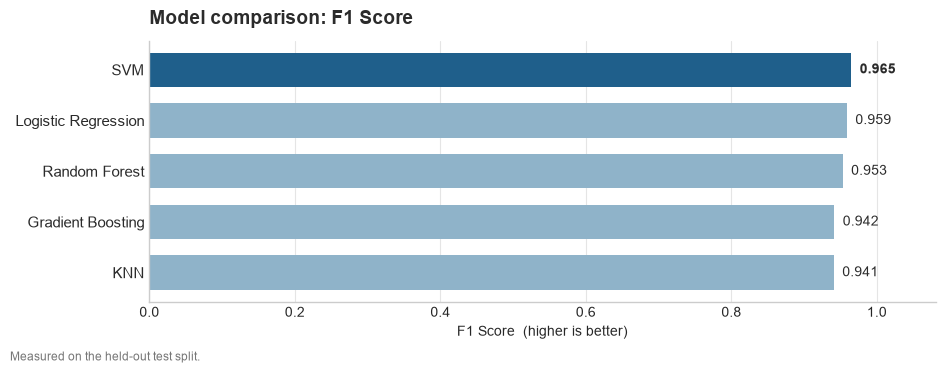

In [8]:
clf.plot_comparison(tuned_models)

## 3. Grid search with your own grid and scoring
`param_grids` overrides the default space for the named model; `scoring` is any scikit-learn scorer.

In [9]:
m = clf.tune_models(include=['knn'], search='grid', cv=5, scoring='f1',
                    param_grids={'knn': {'n_neighbors': [3, 5, 7, 9], 'weights': ['uniform', 'distance']}})
clf.tuning_results_

,Model,Best CV f1,Best Params,Candidates,Search Time (s)
0,KNN,0.976546,"{'n_neighbors': 7, 'weights': 'uniform'}",8,0.308437


## 4. Halving search (fast on bigger grids)

In [10]:
clf.tune_models(include=['random_forest'], search='halving', cv=3)
clf.tuning_results_[['Model', 'Best CV accuracy', 'Candidates', 'Search Time (s)']]

,Model,Best CV accuracy,Candidates,Search Time (s)
0,Random Forest,0.972222,30,17.177532


## 5. Regression tuning (including SVR, whose target is scaled internally)

In [11]:
Xr, yr = make_regression(n_samples=400, n_features=8, noise=15, random_state=1)
reg = MultiModelRegressor(Xr, yr, random_state=1, verbose=False)
reg_base = reg.show_tabular_report(reg.run_all_models(include=['ridge', 'svr', 'random_forest']), sort_by='RMSE', return_df=True)


 REGRESSION MODEL COMPARISON TABLE 
                  Model       MAE         MSE      RMSE  R2 Score  Fit Time (s)
       Ridge Regression 12.851746  279.531877 16.719207  0.988640      0.000592
                    SVR 32.646655 2450.458095 49.502102  0.900415      0.003134
Random Forest Regressor 51.786068 4689.087387 68.476911  0.809439      0.061786

* BEST MODEL RECOMMENDATION (by RMSE): Ridge Regression
   R2 Score: 0.9886 | RMSE: 16.7192



In [12]:
rm = reg.tune_models(include=['ridge', 'svr', 'random_forest'], n_iter=10, cv=5)
reg.tuning_results_

,Model,Best CV r2,Best Params,Candidates,Search Time (s)
0,Ridge Regression,0.989965,{'alpha': 0.1},5,0.040189
1,SVR,0.922987,"{'gamma': 'auto', 'epsilon': 0.01, 'C': 10}",10,0.301314
2,Random Forest Regressor,0.784013,"{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_fe...",10,6.945924


In [13]:
reg.show_tabular_report(rm, sort_by='RMSE', return_df=True)


 REGRESSION MODEL COMPARISON TABLE 
                  Model       MAE         MSE      RMSE  R2 Score  Fit Time (s)
       Ridge Regression 12.804007  277.963826 16.672247  0.988704      0.000387
                    SVR 25.199044 1530.701180 39.124176  0.937793      0.011930
Random Forest Regressor 51.752927 4814.343961 69.385474  0.804348      0.123874

* BEST MODEL RECOMMENDATION (by RMSE): Ridge Regression
   R2 Score: 0.9887 | RMSE: 16.6722



,Model,MAE,MSE,RMSE,R2 Score,Fit Time (s)
0,Ridge Regression,12.804007,277.963826,16.672247,0.988704,0.000387
1,SVR,25.199044,1530.701180,39.124176,0.937793,0.011930
2,Random Forest Regressor,51.752927,4814.343961,69.385474,0.804348,0.123874


## 6. Tuning works with `preprocess=True` on messy data
Missing values and text columns are handled inside each CV fold.

In [14]:
import numpy as np
rng = np.random.default_rng(1)
n = 300
X = pd.DataFrame({'a': rng.normal(size=n), 'b': rng.normal(size=n), 'c': rng.choice(['red', 'green'], n)})
X.loc[rng.choice(n, 20, replace=False), 'a'] = np.nan
y = ((X['b'] + (X['c'] == 'red')) > 0.5).astype(int)
messy = MultiModelClassifier(X, y, preprocess=True, verbose=False)
messy.tune_models(include=['logistic_regression', 'random_forest'], n_iter=5, cv=3)
messy.tuning_results_[['Model', 'Best CV accuracy', 'Best Params']]

,Model,Best CV accuracy,Best Params
0,Random Forest,1.000000,"{'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_f..."
1,Logistic Regression,0.995238,{'C': 100}


In [15]:
messy.predict(X.head(5), model='Logistic Regression')

array([0, 0, 0, 0, 0])

## 7. Failures are recorded, not raised
A bad grid for one model does not stop the others.

In [16]:
out = clf.tune_models(include=['naive_bayes', 'knn'], cv=3, param_grids={'naive_bayes': {'bogus': [1, 2]}})
print([m[0] for m in out])
print(clf.failed_models_)

[WARNING] Model 'Naive Bayes' failed to train or evaluate: Invalid parameter 'bogus' for estimator GaussianNB(). Valid parameters are: ['priors', 'var_smoothing'].
['KNN']
{'Naive Bayes': "ValueError: Invalid parameter 'bogus' for estimator GaussianNB(). Valid parameters are: ['priors', 'var_smoothing']."}


## 8. Save the tuned model and reload it

In [17]:
import tempfile, os
clf.tune_models(include=['logistic_regression'], cv=3)  # each run replaces the fitted models, so tune the one we save
path =os.path.join(tempfile.mkdtemp(), 'best.joblib')
clf.save_model(path, model='Logistic Regression')
loaded = mm.load_model(path)
print(loaded.predict(bc.data.head(5)))
print(bc.target.head(5).tolist())

[0 0 0 0 0]
[0, 0, 0, 0, 0]
